In [1]:
# 사전 작업

In [2]:
from scheduler.service.cv_ai_trainer_s1_gen02 import *

2025-05-30 12:46:16.089749: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-30 12:46:16.089935: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
cv_ai_trainer = CvAiTrainerS1Gen02(seq=11)

In [4]:
df = cv_ai_trainer.get_dataframe()

In [5]:
# 수치화 변경 
features = cv_ai_trainer.features

df_f = df.copy()

# 1. features가 실제 컬럼에 있는지 확인
valid_features = [col for col in features if col in df_f.columns]
print("유효한 feature 수:", len(valid_features))
print(valid_features)

# 숫자형으로 변환 가능한 feature만 수동 변환 시도
df_f = df_f.apply(pd.to_numeric, errors='coerce')

유효한 feature 수: 77
['timestamp', 'weekday', 'open', 'high', 'low', 'close', 'volume', 'volume_ma5', 'volume_ma20', 'volume_ratio', 'obv', 'vwap', 'volume_volatility', 'volume_spike', 'rsi', 'macd', 'macd_signal', 'bollinger_partition', 'bollinger_partition_prev', 'atr', 'cci', 'stochastic_k', 'stochastic_d', 'roc', 'momentum', 'ema_cross_up', 'cdl2crows', 'cdl3blackcrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside', 'cdl3starsinsouth', 'cdl3whitesoldiers', 'cdlabandonedbaby', 'cdladvanceblock', 'cdlbelthold', 'cdlbreakaway', 'cdlclosingmarubozu', 'cdlconcealbabyswall', 'cdlcounterattack', 'cdldarkcloudcover', 'cdldoji', 'cdldojistar', 'cdldragonflydoji', 'cdlengulfing', 'cdleveningdojistar', 'cdleveningstar', 'cdlgapsidesidewhite', 'cdlgravestonedoji', 'cdlhammer', 'cdlhangingman', 'cdlharami', 'cdlharamicross', 'cdlhighwave', 'cdlhikkake', 'cdlhikkakemod', 'cdlhomingpigeon', 'cdlidentical3crows', 'cdlinneck', 'cdlinvertedhammer', 'cdlkicking', 'cdlkickingbylength', 'cdlladderbottom'

In [6]:
# 파생변수 
df_f['high_low_ratio'] = df_f['high'] / df_f['low']
df_f['close_open_ratio'] = df_f['close'] / df_f['open']
df_f['daily_range'] = (df_f['high'] - df_f['low']) / df_f['close']
df_f['price_change_ratio'] = (df_f['close'] - df_f['open']) / df_f['open']
df_f['rolling_volatility'] = df_f['close'].pct_change().rolling(10).std()
df_f['close_above_ma5'] = (df_f['close'] > df_f['close'].rolling(5).mean()).astype(int)

# 1. 고저 비율 (급등락 감지)
df_f['high_low_ratio'] = df_f['high'] / df_f['low']

# 2. 캔들 몸통 크기
df_f['candle_body_size'] = (df_f['close'] - df_f['open']).abs()

# 3. 캔들 윗꼬리 & 아랫꼬리 비율
df_f['upper_wick'] = df_f['high'] - df_f[['open', 'close']].max(axis=1)
df_f['lower_wick'] = df_f[['open', 'close']].min(axis=1) - df_f['low']
df_f['wick_ratio'] = (df_f['upper_wick'] + df_f['lower_wick']) / df_f['high'] - df_f['low'] + 1e-6

# 4. 1시간(=12개) 변동성 지표
df_f['volatility_1h'] = df_f['close'].pct_change().rolling(12).std()

# 5. 30분 평균 대비 갭
df_f['gap_vs_30min_avg'] = (df_f['open'] - df_f['close'].shift(1)) / df_f['close'].shift(1).rolling(6).mean()

# 6. 볼린저 밴드 너비 (20개 = 100분)
df_f['bollinger_width'] = (
    4 * df_f['close'].rolling(20).std() / df_f['close'].rolling(20).mean()
)

# 7. 이동평균 대비 종가
df_f['close_vs_ma12'] = df_f['close'] / df_f['close'].rolling(12).mean()  # 1시간 평균
df_f['close_vs_ma36'] = df_f['close'] / df_f['close'].rolling(36).mean()  # 3시간 평균

# 피쳐  
features = cv_ai_trainer.features

In [7]:
# 타겟 생성
expr = "2 if ((float(price_after_1day) - float(price_on_time)) / float(price_on_time) * 100) > 1 else (0 if ((float(price_after_1day) - float(price_on_time)) / float(price_on_time) * 100) < -1 else 1)"
df_t = cv_ai_trainer.apply_derived_to_df(df, expr, "change_after_1day")
df_t = df[['change_after_1day']]

In [8]:
df_combined = pd.concat([df_f, df_t], axis=1)

In [9]:
df_combined_cols = df_combined.columns.tolist()
print(df_combined_cols)

['seq', 'ticker', 'tick_datetime', 'timestamp', 'weekday', 'open', 'high', 'low', 'close', 'volume', 'volume_ma5', 'volume_ma20', 'volume_ratio', 'obv', 'vwap', 'volume_volatility', 'volume_spike', 'rsi', 'macd', 'macd_signal', 'bollinger_partition', 'bollinger_partition_prev', 'atr', 'cci', 'stochastic_k', 'stochastic_d', 'roc', 'momentum', 'ema_cross_up', 'cdl2crows', 'cdl3blackcrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside', 'cdl3starsinsouth', 'cdl3whitesoldiers', 'cdlabandonedbaby', 'cdladvanceblock', 'cdlbelthold', 'cdlbreakaway', 'cdlclosingmarubozu', 'cdlconcealbabyswall', 'cdlcounterattack', 'cdldarkcloudcover', 'cdldoji', 'cdldojistar', 'cdldragonflydoji', 'cdlengulfing', 'cdleveningdojistar', 'cdleveningstar', 'cdlgapsidesidewhite', 'cdlgravestonedoji', 'cdlhammer', 'cdlhangingman', 'cdlharami', 'cdlharamicross', 'cdlhighwave', 'cdlhikkake', 'cdlhikkakemod', 'cdlhomingpigeon', 'cdlidentical3crows', 'cdlinneck', 'cdlinvertedhammer', 'cdlkicking', 'cdlkickingbylength', '

In [10]:
# 상관관계 분석 (Correlation Analysis)
import numpy as np

def get_top_correlations(corr_matrix, n=20):
    # 삼각행렬 상부만 추출하여 중복 제거
    corr_matrix_no_self = corr_matrix.where(~np.eye(corr_matrix.shape[0], dtype=bool))
    upper = corr_matrix_no_self.where(np.triu(np.ones(corr_matrix_no_self.shape), k=1).astype(bool))
    
    top = upper.abs().stack().sort_values(ascending=False).head(n)
    return top
    
corr = df_f.corr()
top_correlations = get_top_correlations(corr, n=50)
print(top_correlations)

close_open_ratio   price_change_ratio    1.000000
low                wick_ratio            1.000000
cdl3blackcrows     cdl3starsinsouth      1.000000
tick_datetime      timestamp             1.000000
seq                timestamp             1.000000
                   tick_datetime         1.000000
high_low_ratio     daily_range           0.999987
open               low                   0.999867
                   wick_ratio            0.999867
low                close                 0.999866
close              wick_ratio            0.999866
high               close                 0.999864
open               high                  0.999852
                   close                 0.999764
close              price_on_time         0.999754
high               low                   0.999748
                   wick_ratio            0.999748
low                price_on_time         0.999626
price_on_time      wick_ratio            0.999626
high               price_on_time         0.999625


In [11]:
# 클래스 불균형 검사
res = df_combined['change_after_1day'].value_counts(normalize=True)
print(res)

1    0.486581
2    0.304635
0    0.208784
Name: change_after_1day, dtype: float64


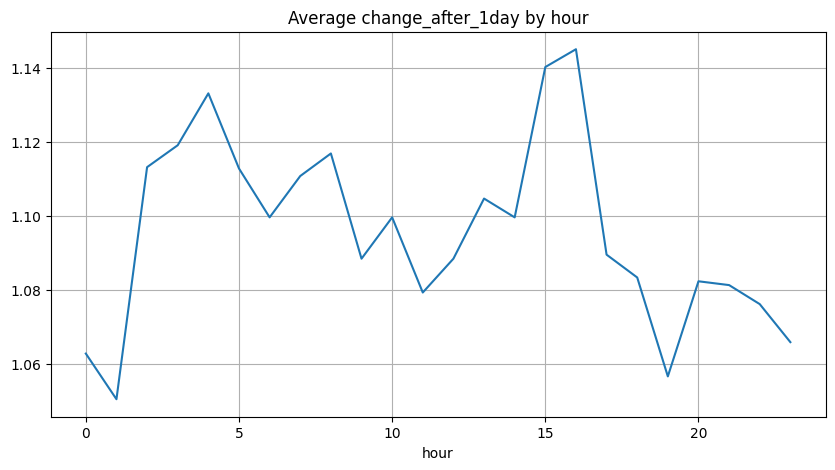

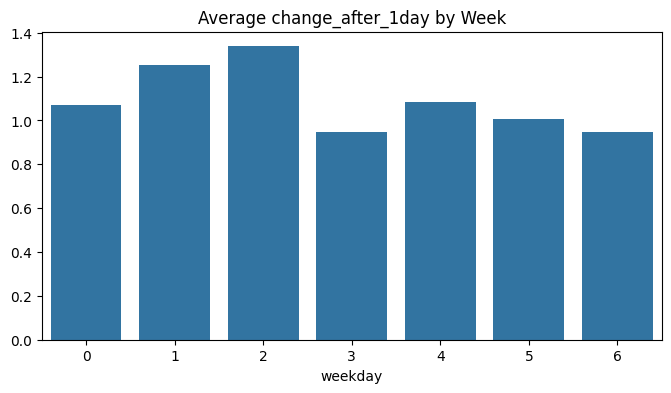

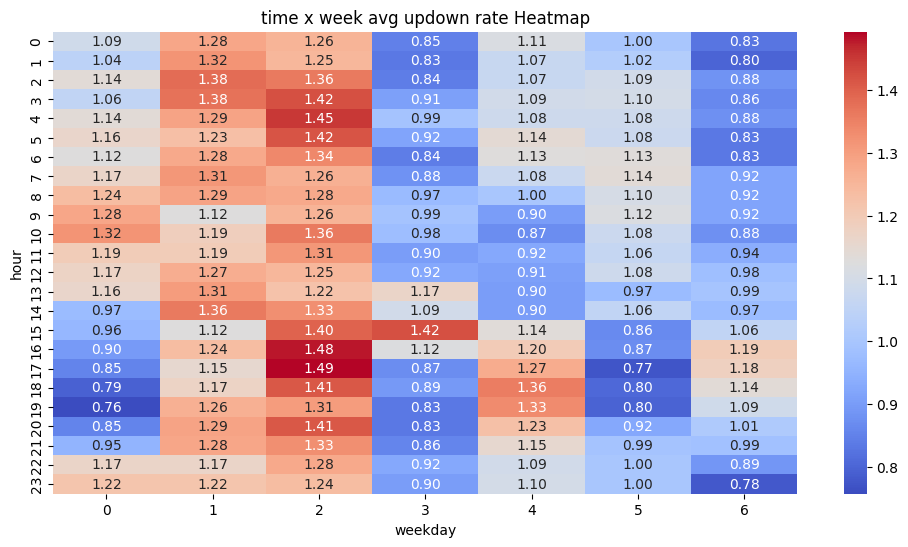

In [12]:
# 시간 특이점 검사
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

df_combined['change_after_1day'] = pd.to_numeric(df_combined['change_after_1day'], errors='coerce')

# 1. timestamp 컬럼 datetime 변환 (unit='s' 또는 'ms' 꼭 지정)
df_combined['timestamp'] = pd.to_datetime(df_combined['timestamp'], unit='s')

# 2. 시간대 추출 (예: 시(hour))
df_combined['hour'] = df_combined['timestamp'].dt.hour

# 3) 시간대별 평균 등락률 (numeric 타입일 경우)
hourly_mean_change = df_combined.groupby('hour')['change_after_1day'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_mean_change.index, y=hourly_mean_change.values)
plt.title('Average change_after_1day by hour')
plt.grid(True)
plt.show()

# 4) 요일별 등락률 평균
weekday_mean_change = df_combined.groupby('weekday')['change_after_1day'].mean()

plt.figure(figsize=(8, 4))
sns.barplot(x=weekday_mean_change.index, y=weekday_mean_change.values)
plt.title('Average change_after_1day by Week')
plt.show()

# 5) 시간대별 x 요일별 heatmap 시각화 (pivot table)
pivot = df_combined.pivot_table(values='change_after_1day', index='hour', columns='weekday', aggfunc='mean')

plt.figure(figsize=(12, 6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('time x week avg updown rate Heatmap')
plt.show()


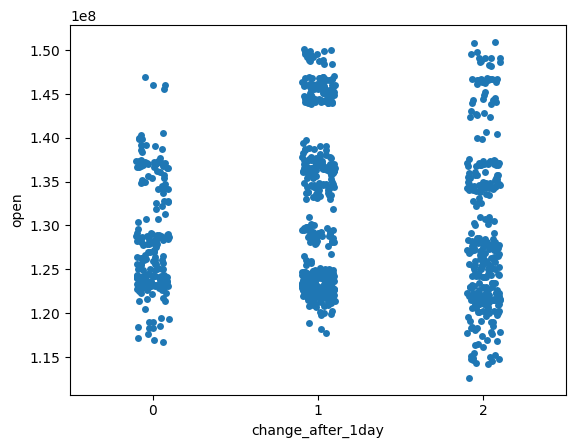

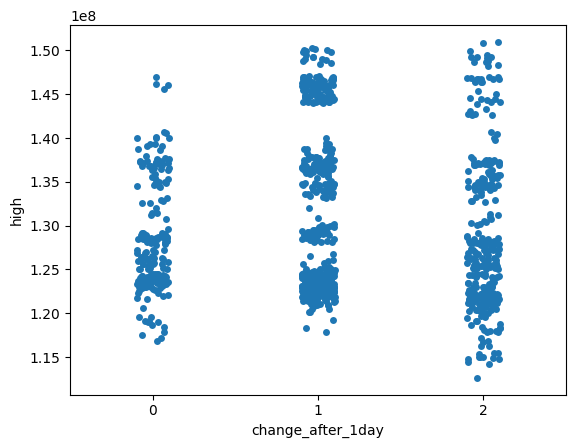

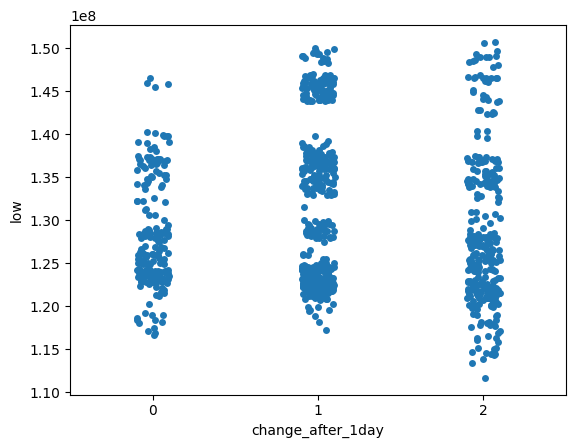

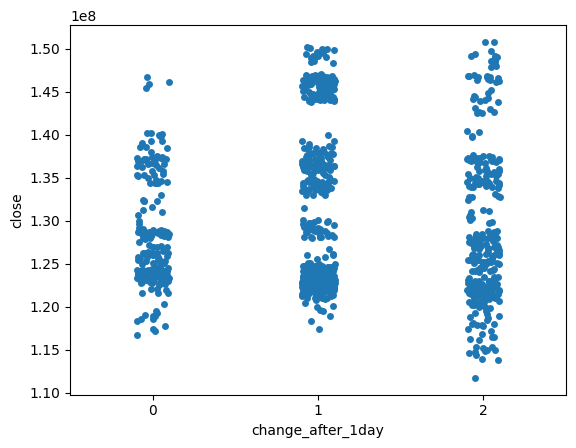

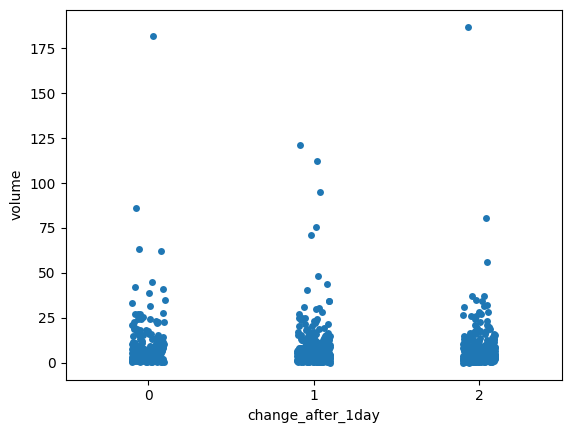

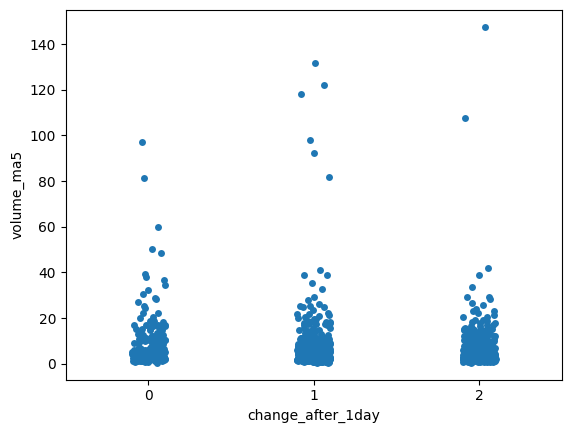

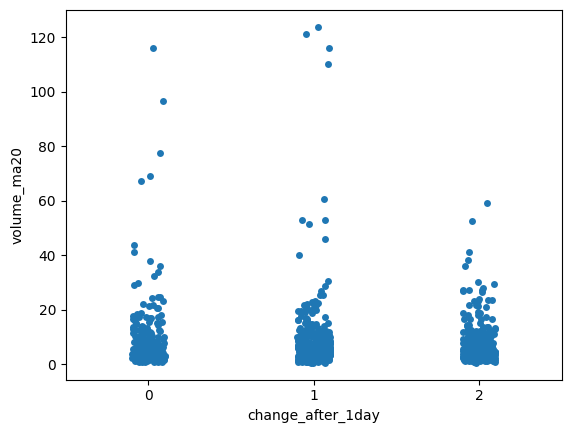

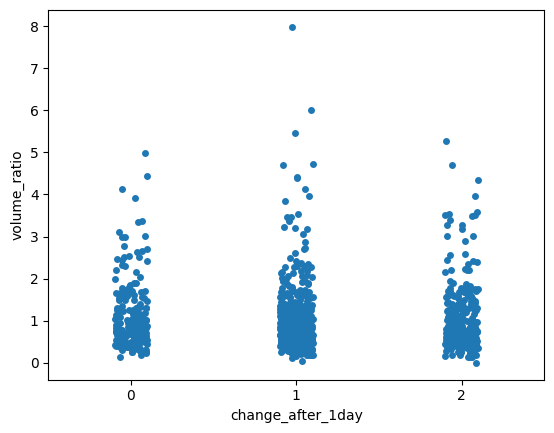

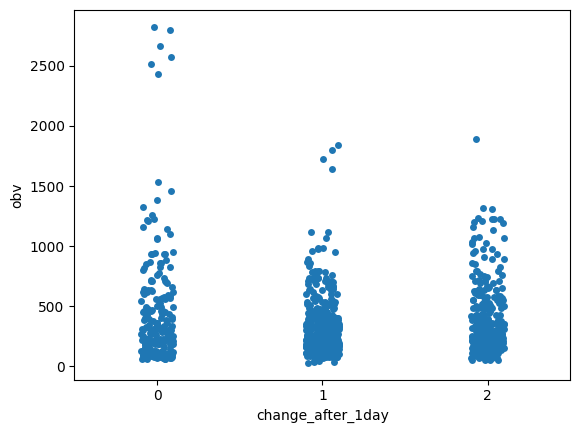

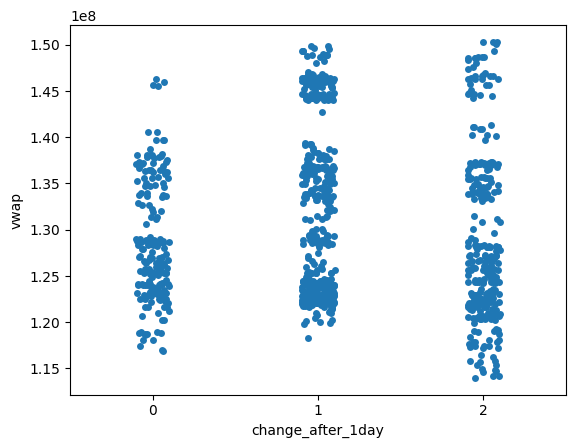

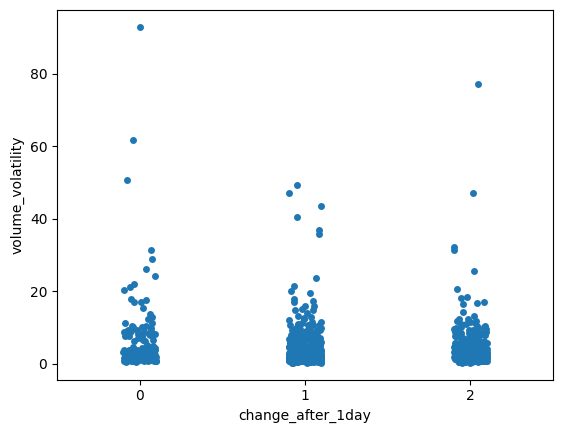

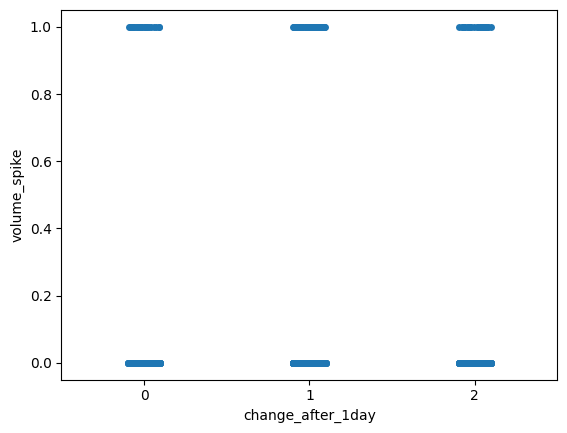

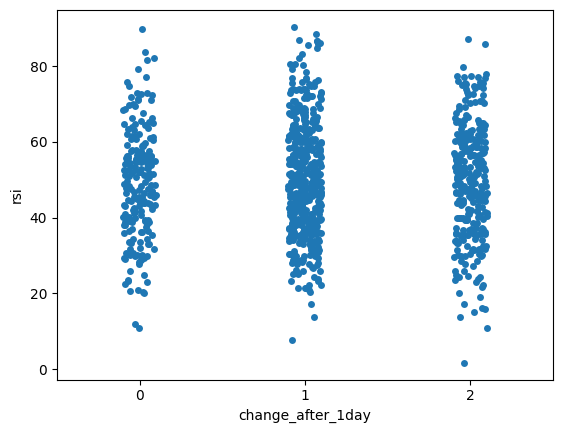

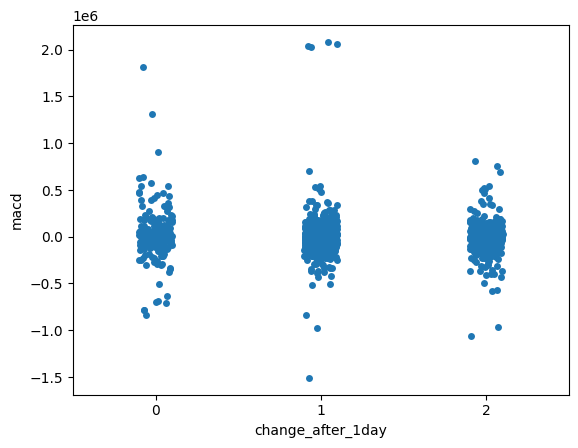

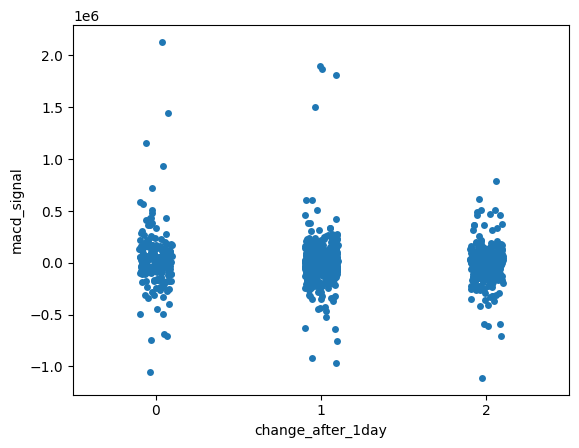

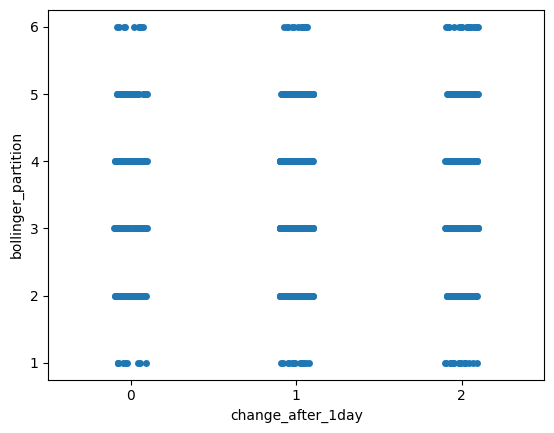

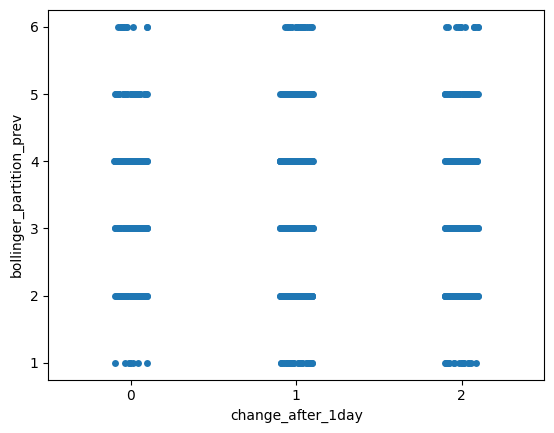

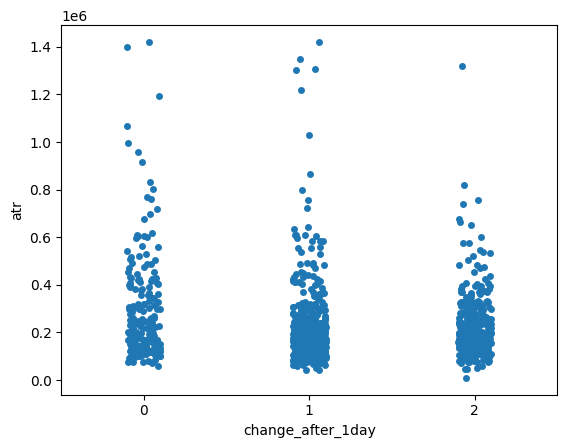

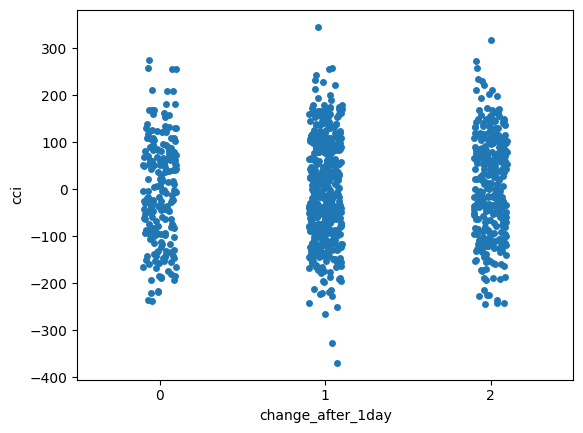

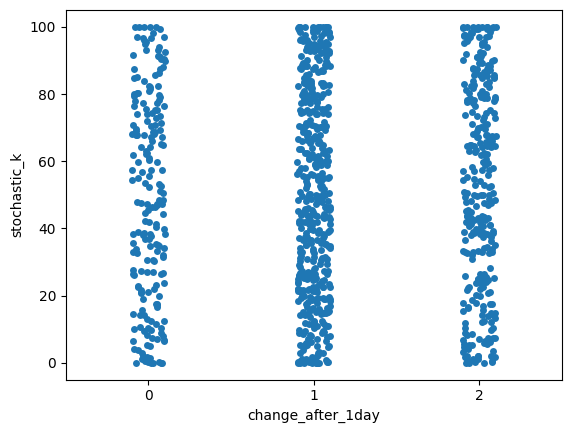

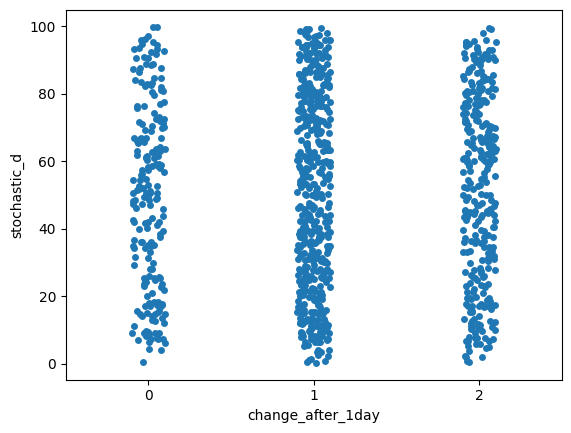

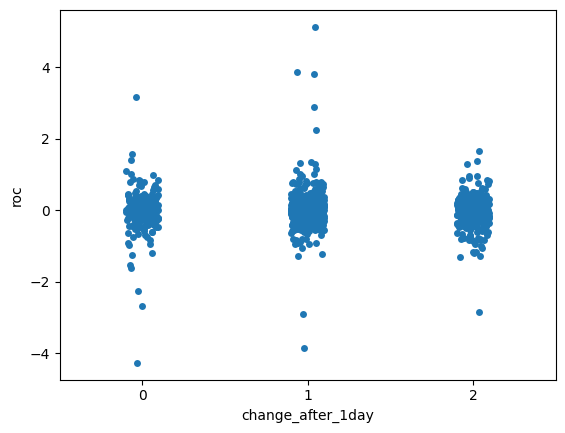

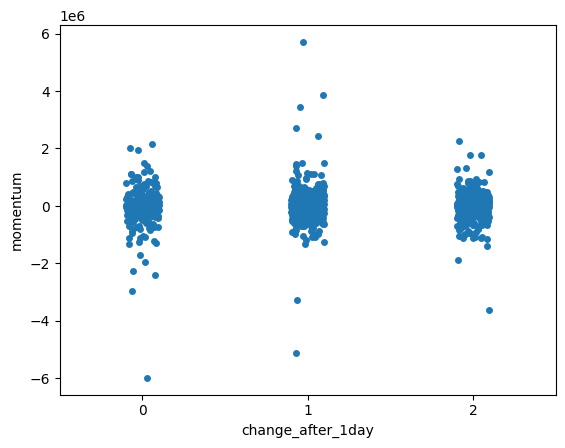

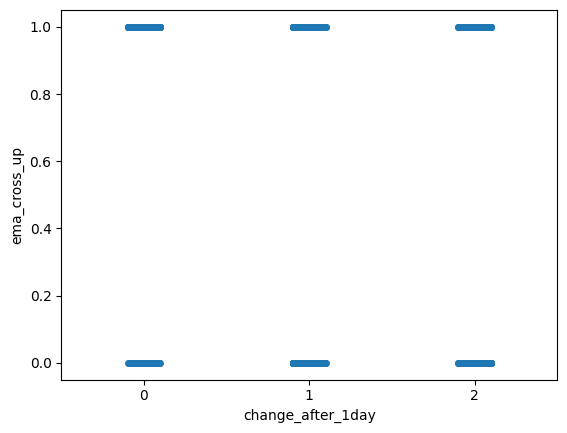

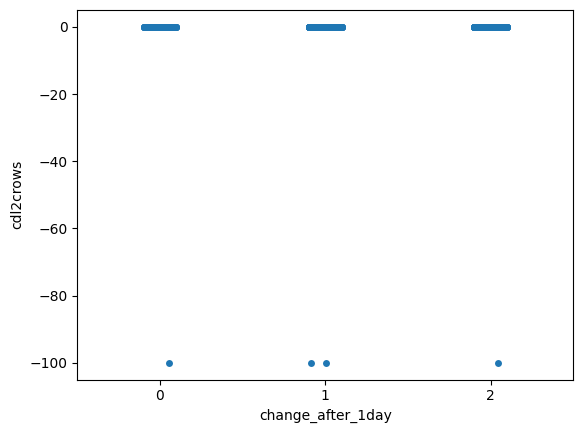

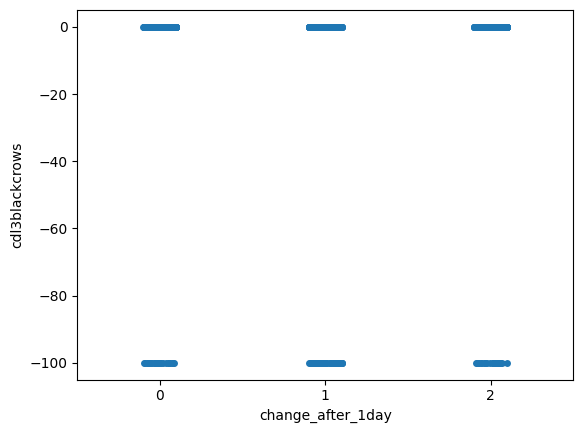

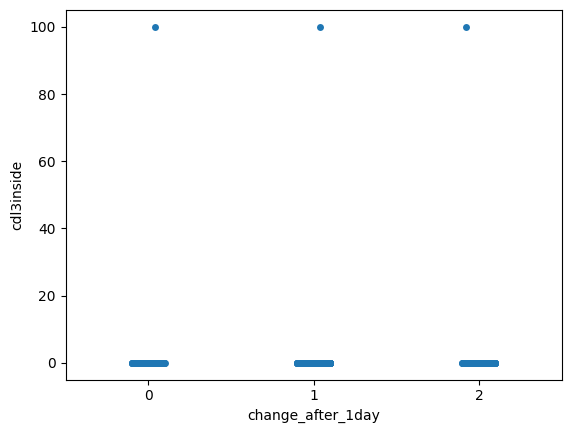

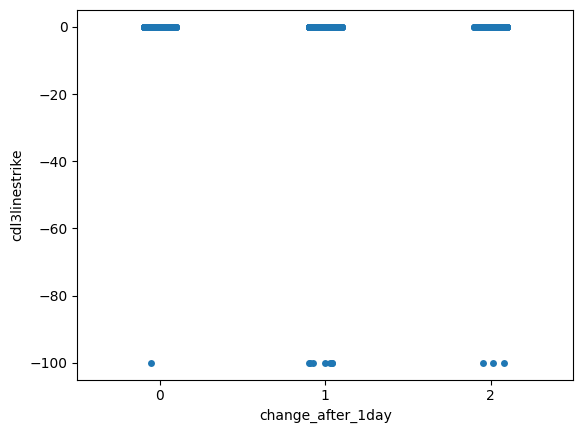

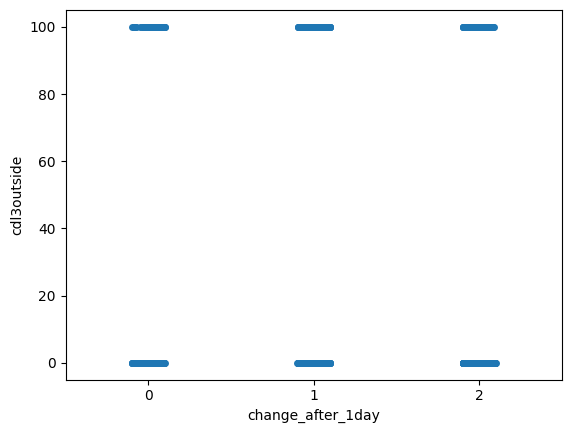

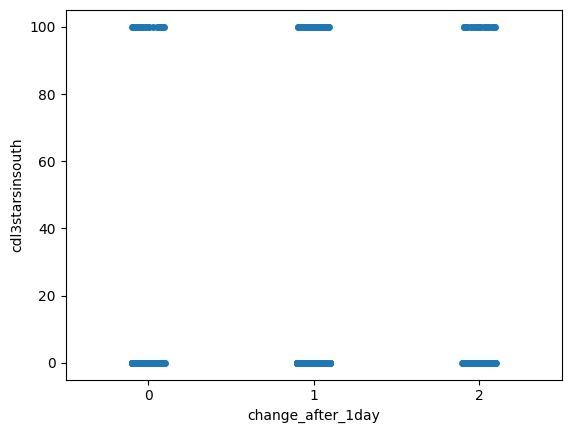

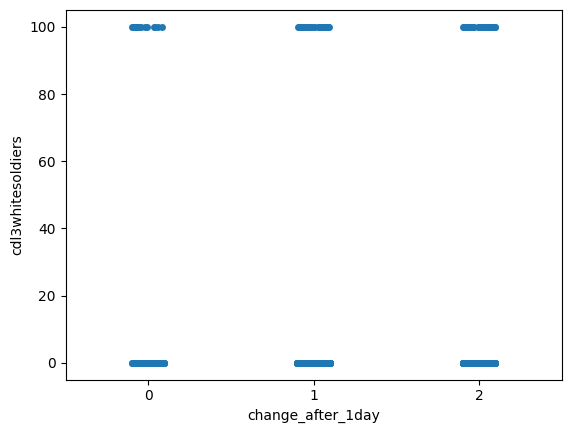

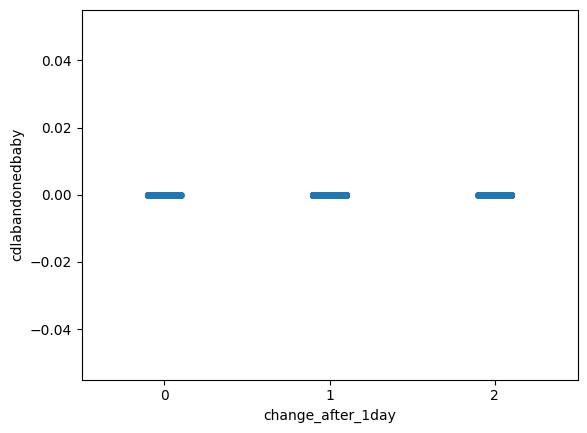

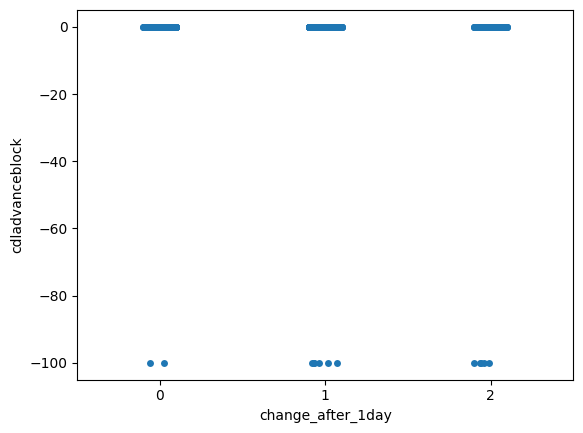

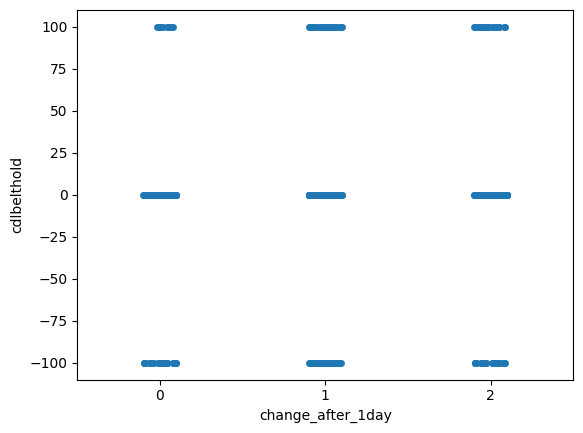

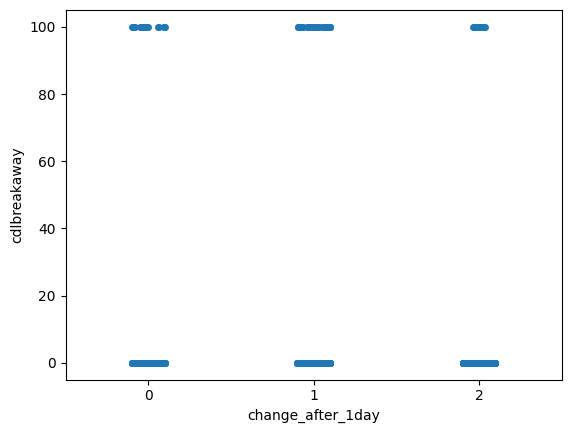

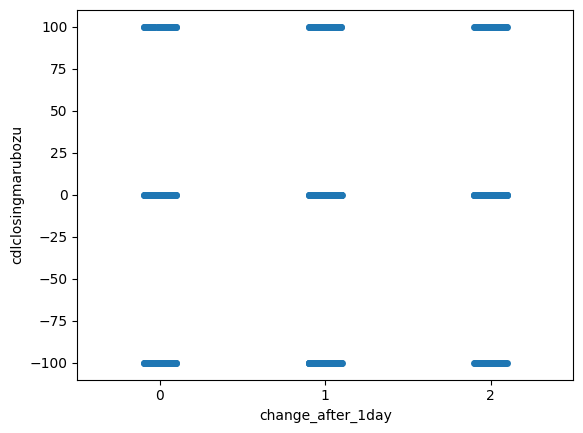

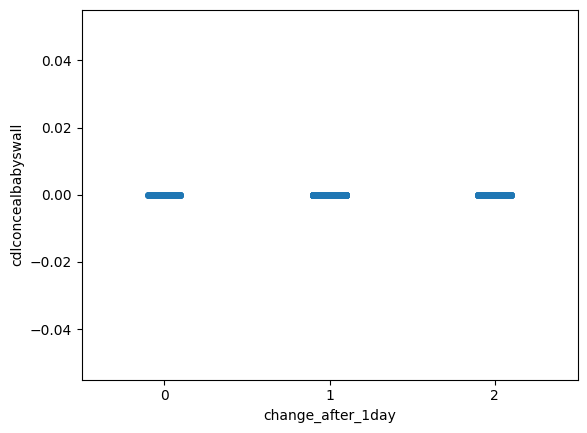

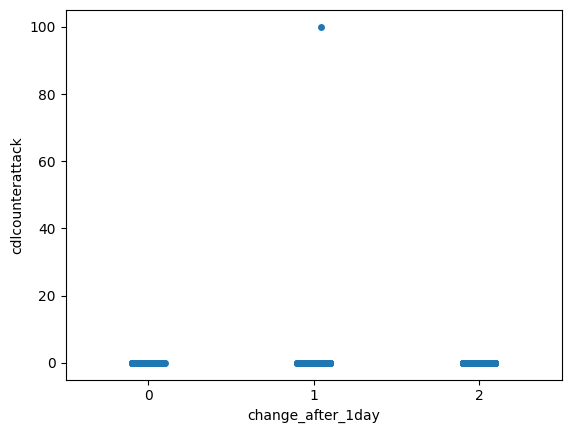

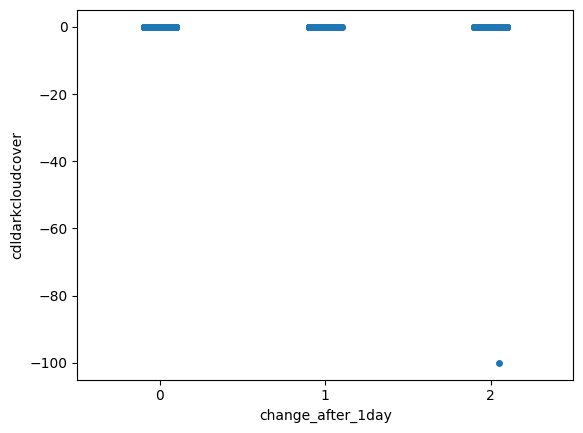

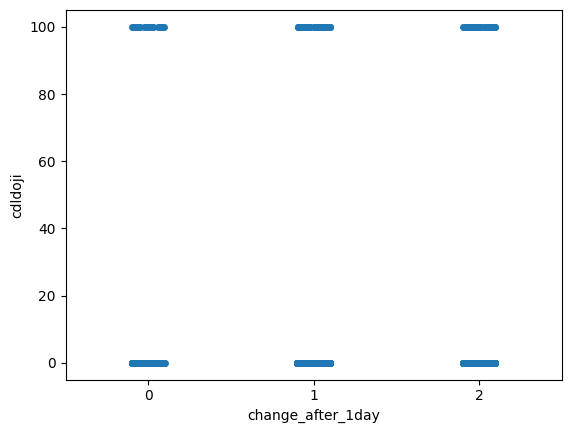

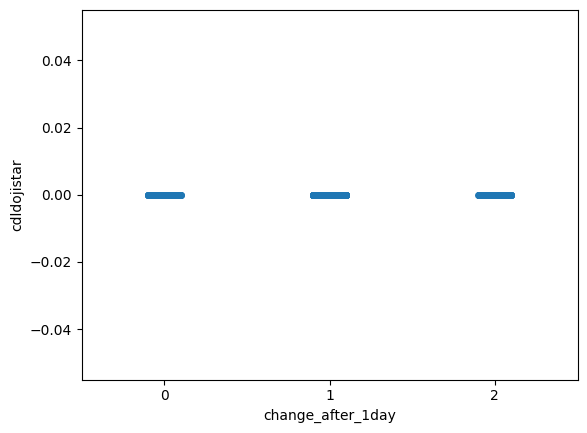

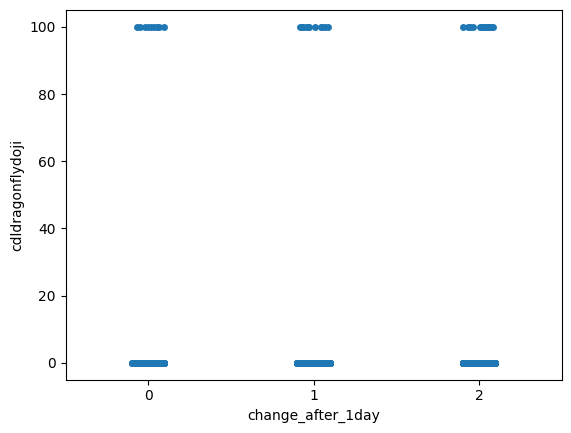

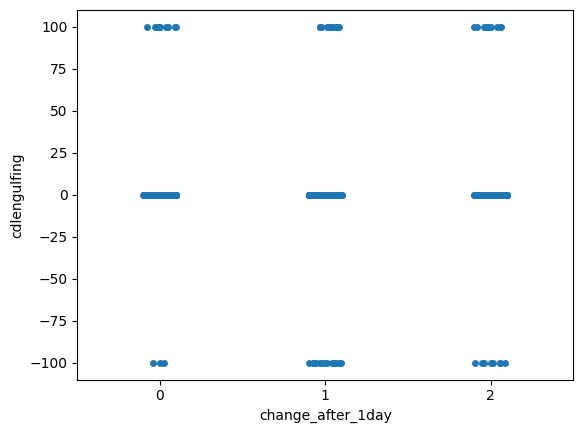

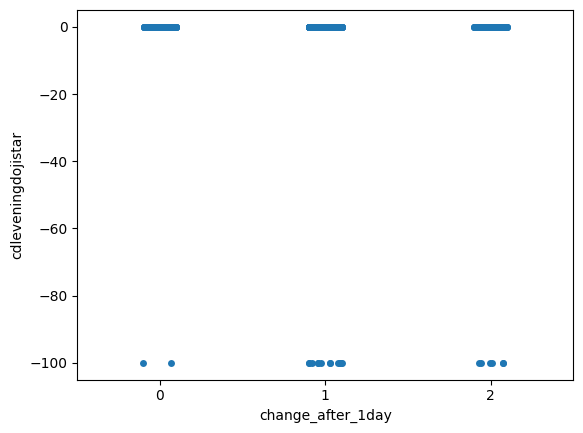

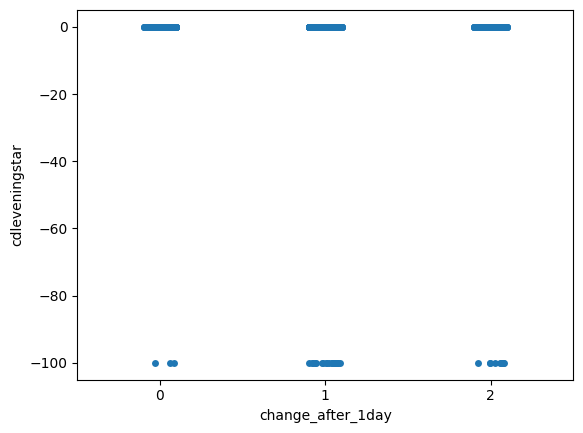

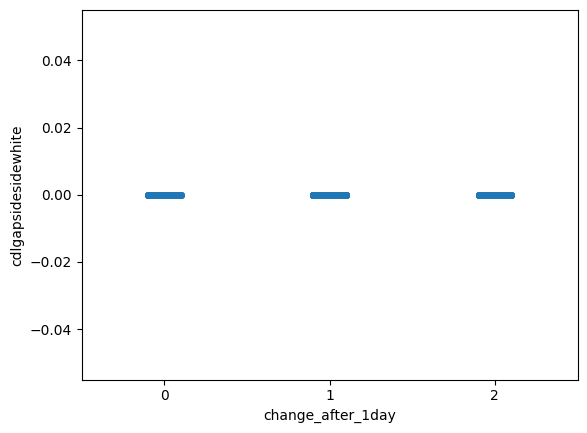

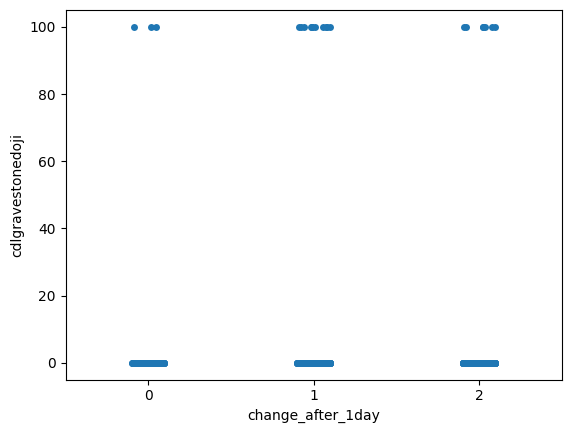

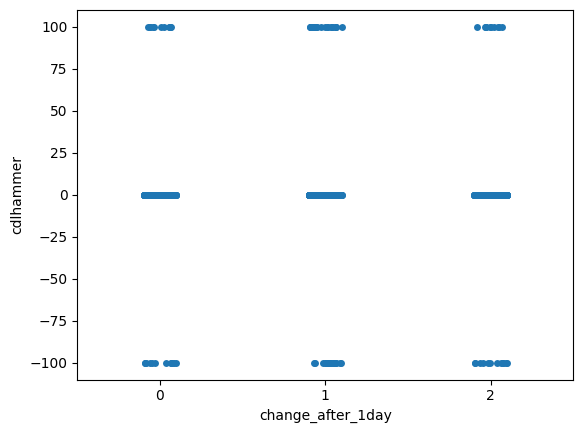

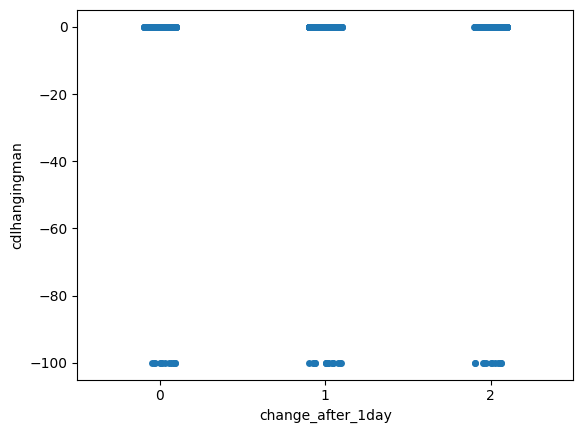

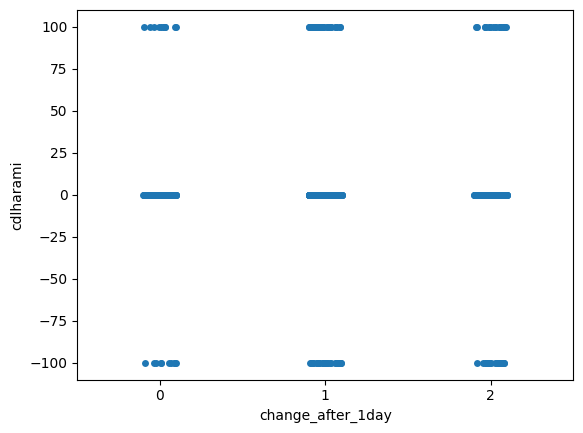

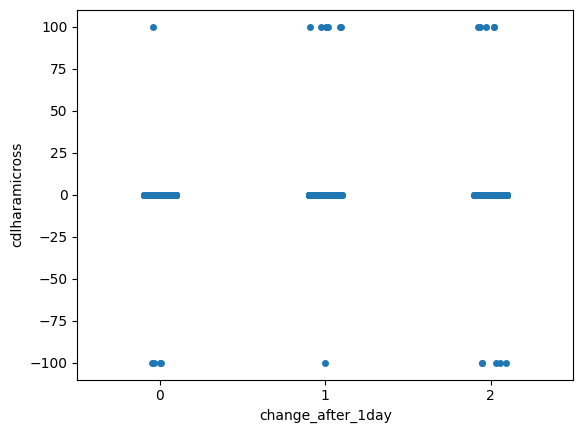

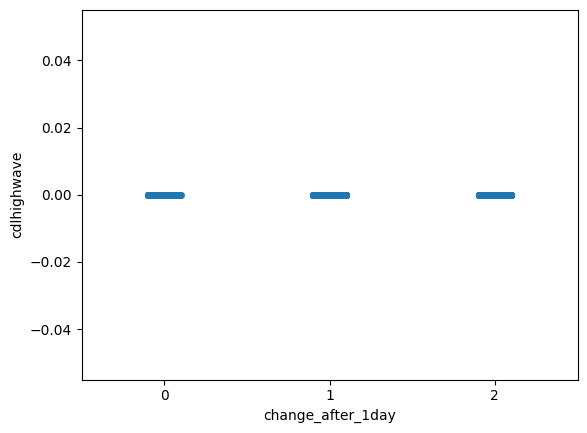

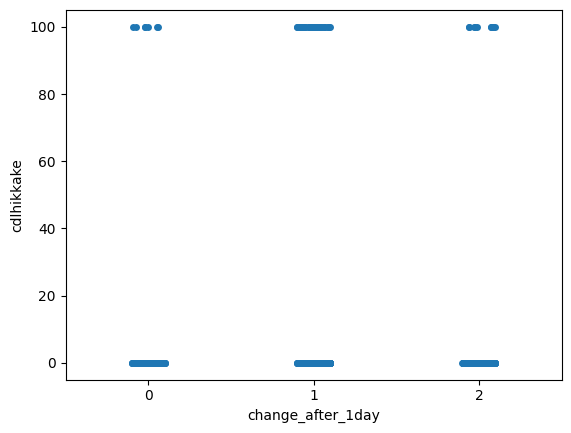

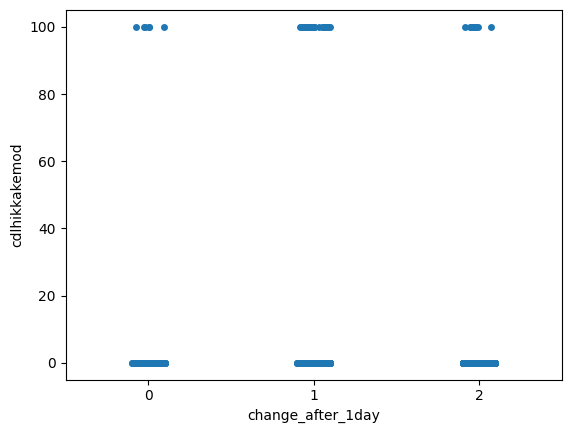

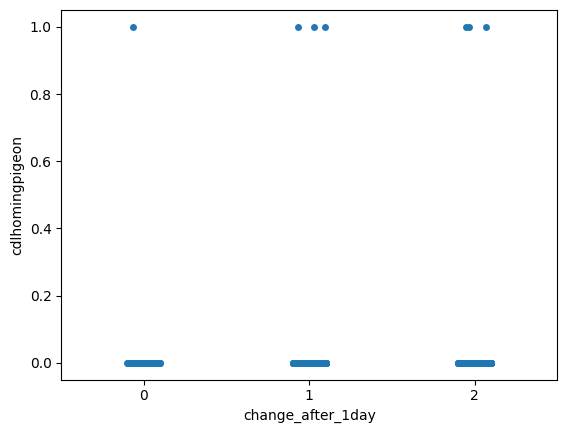

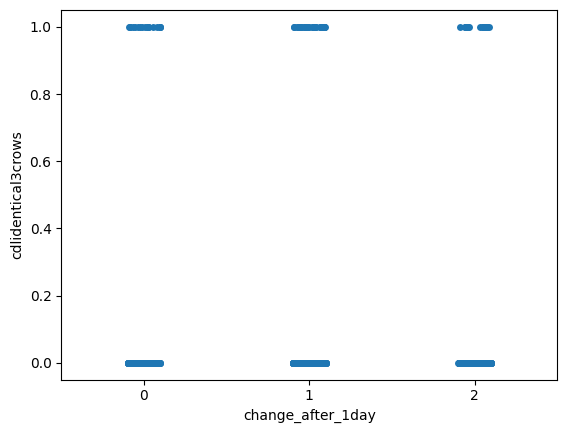

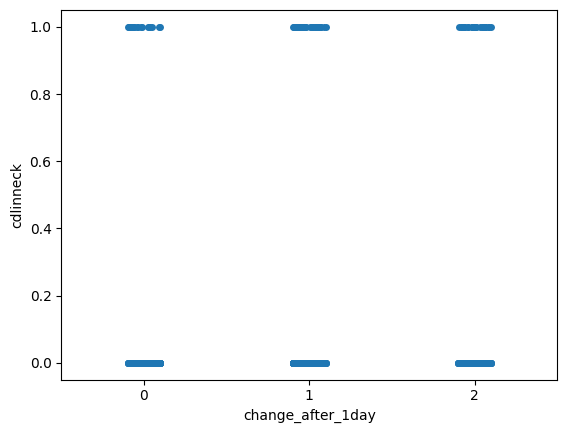

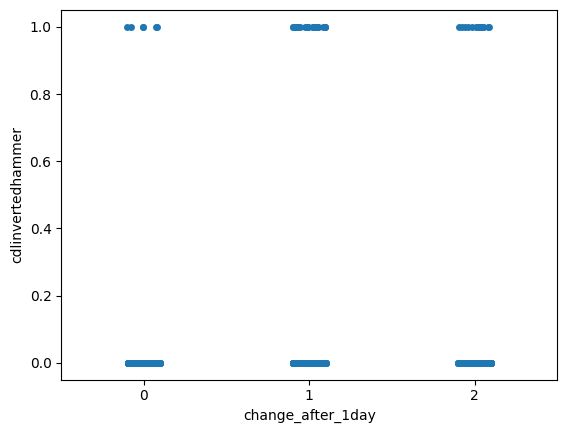

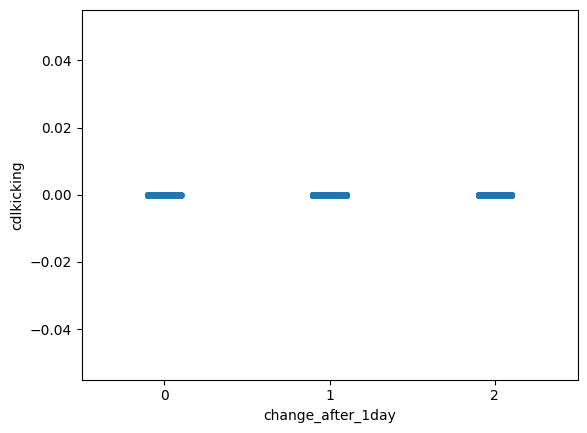

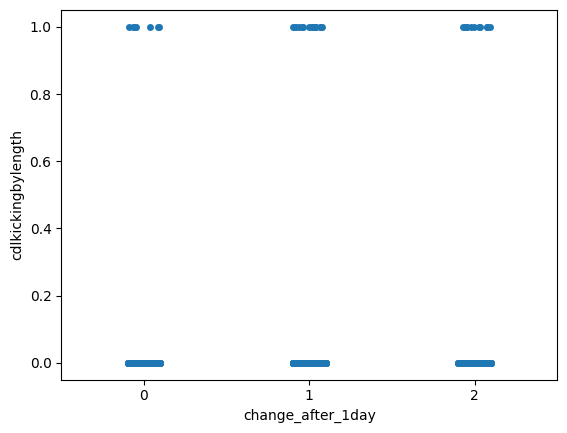

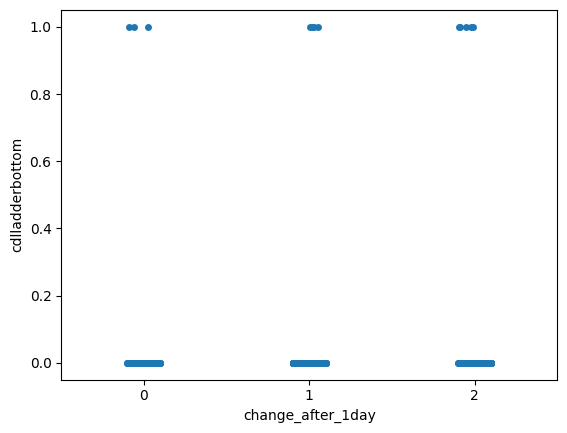

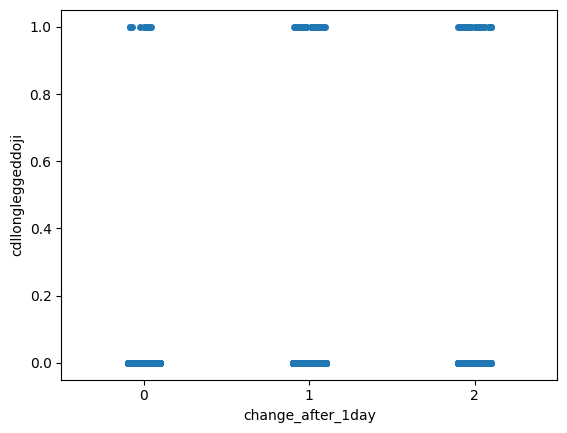

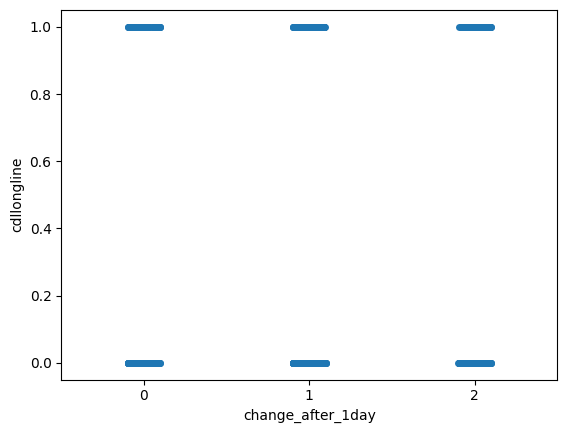

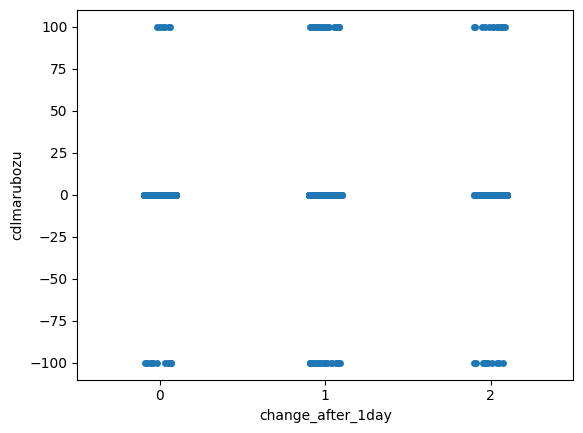

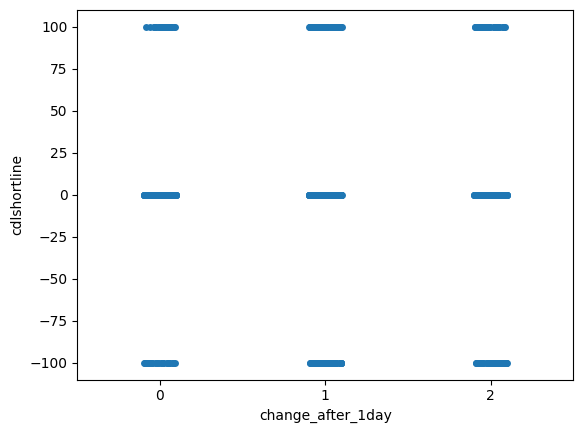

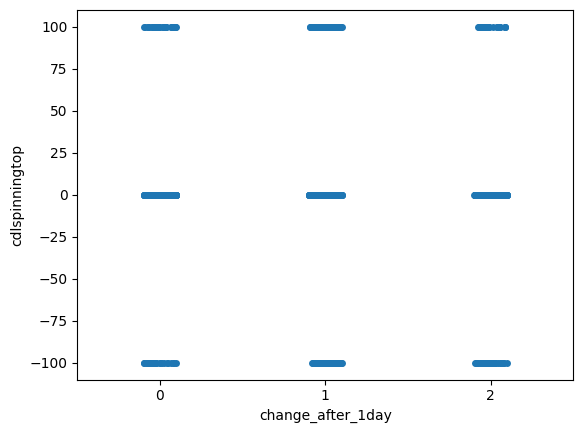

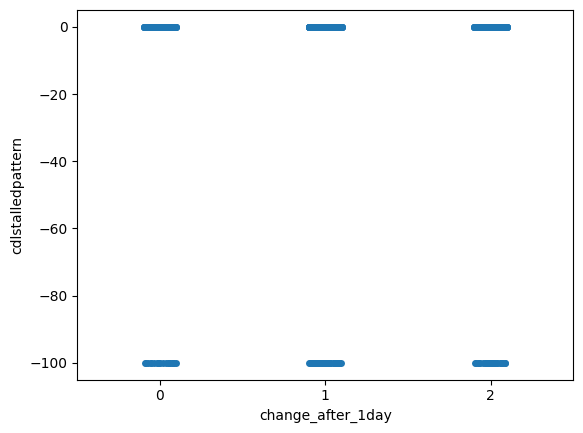

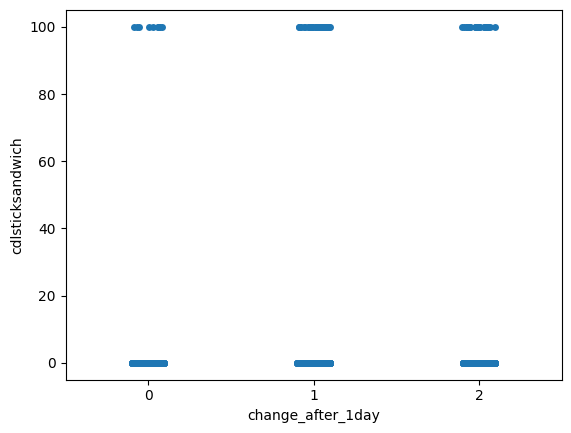

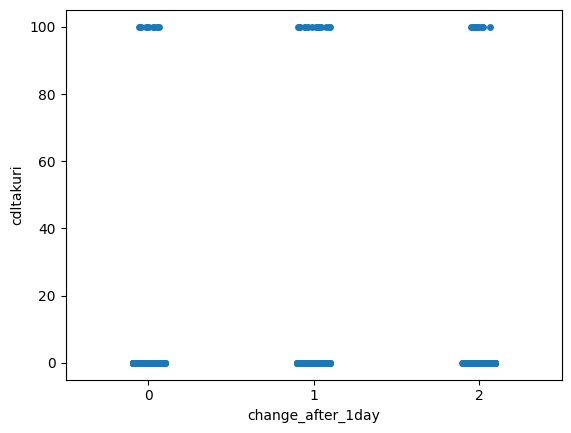

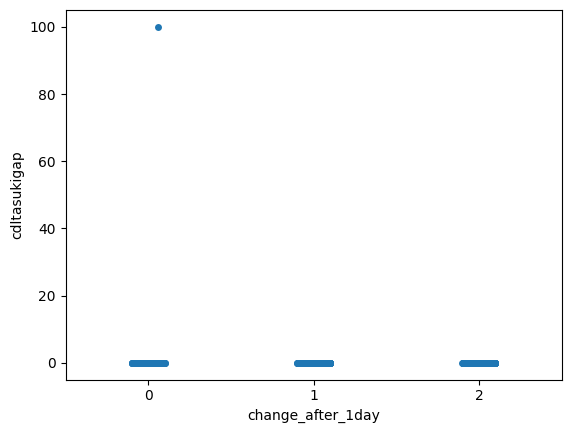

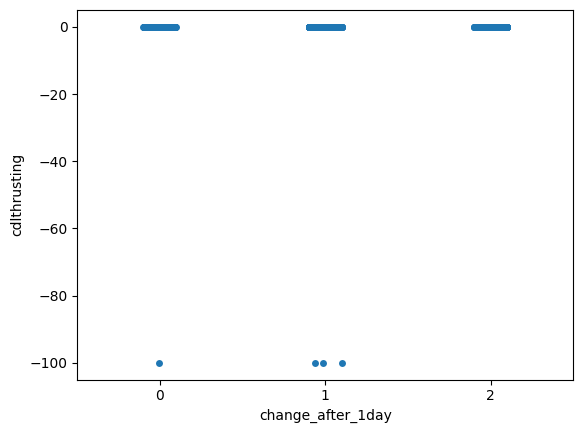

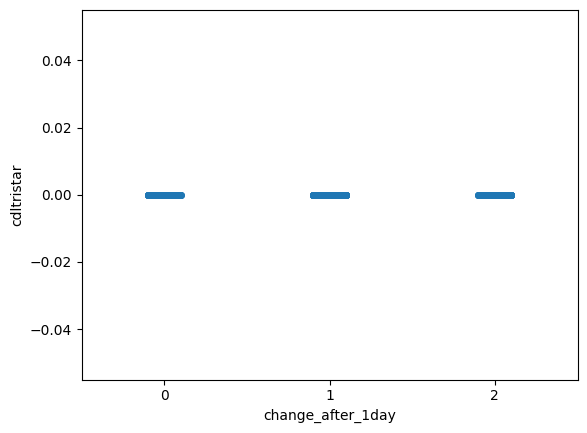

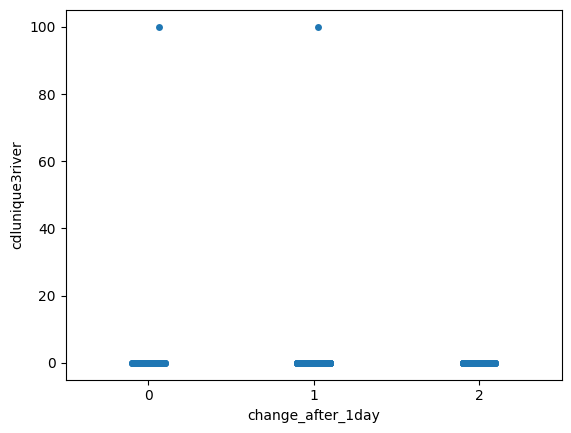

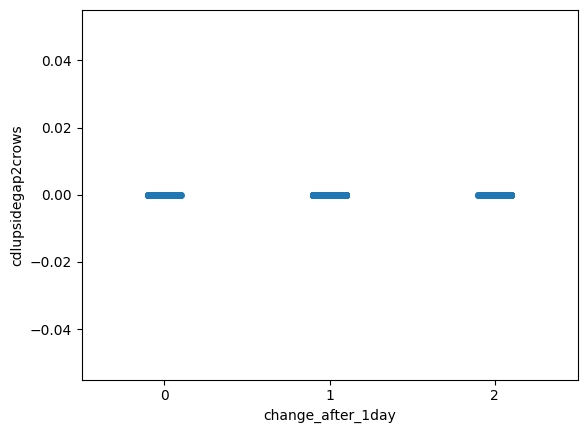

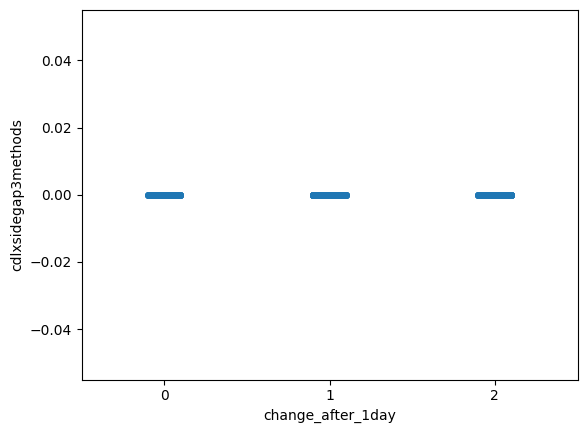

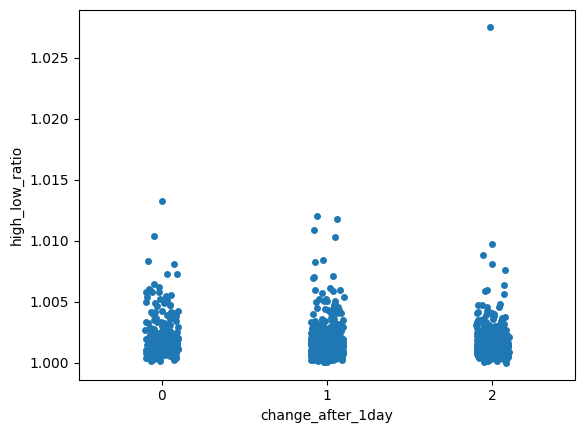

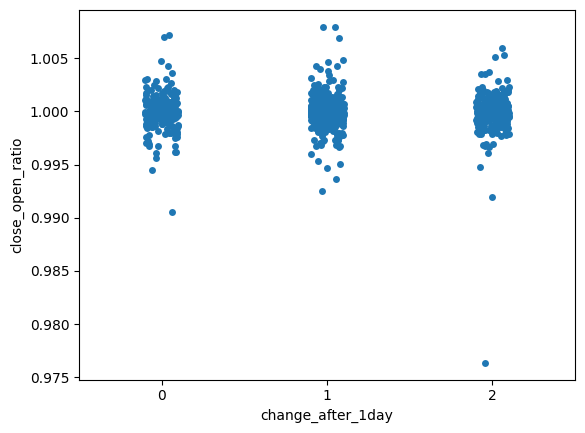

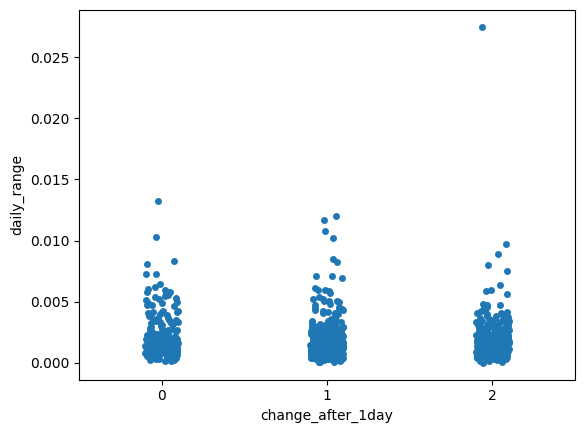

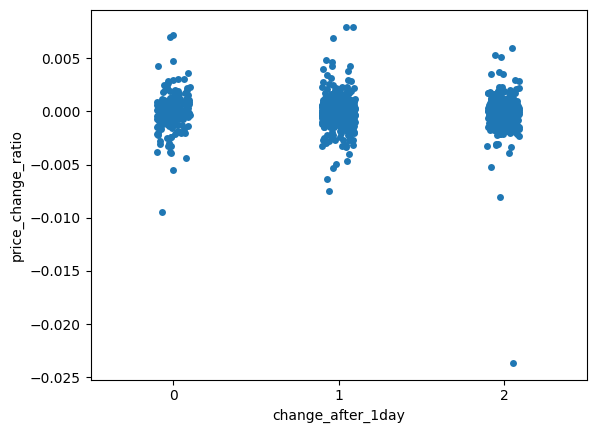

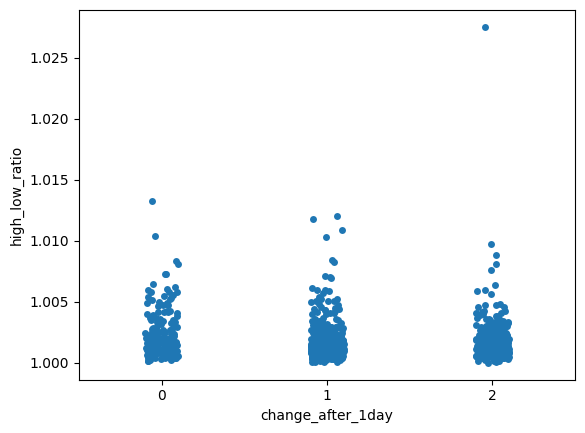

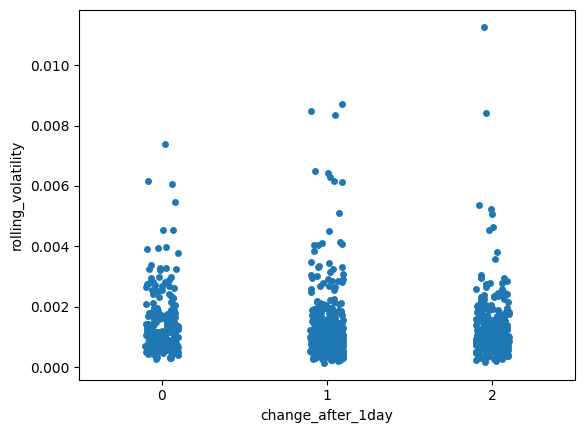

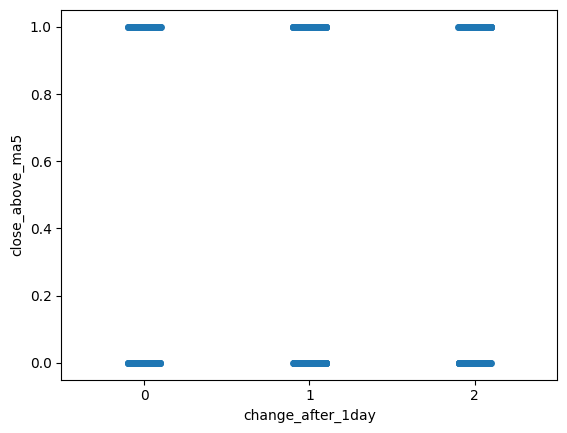

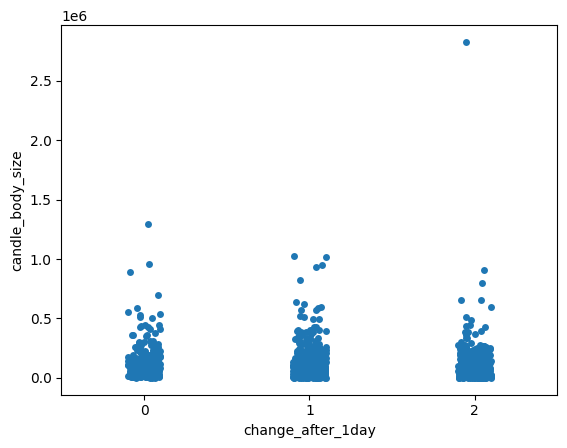

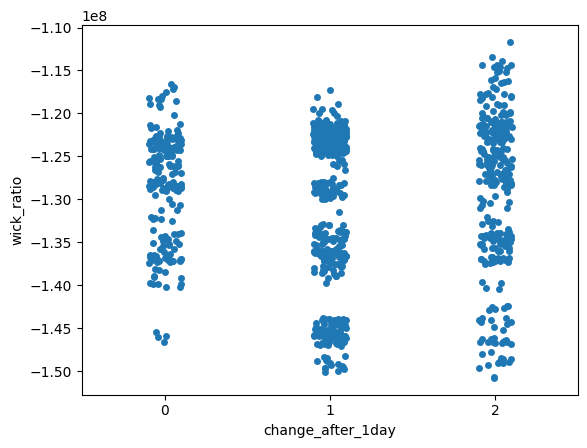

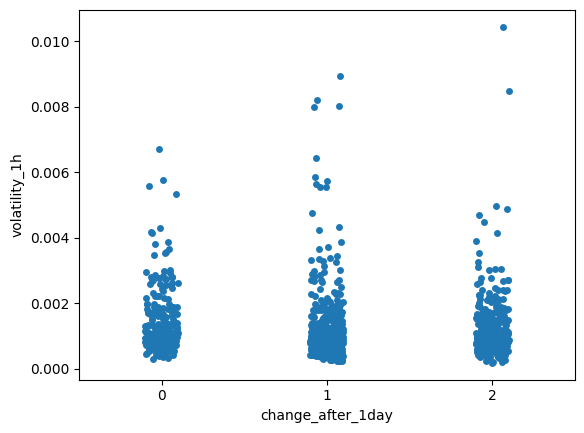

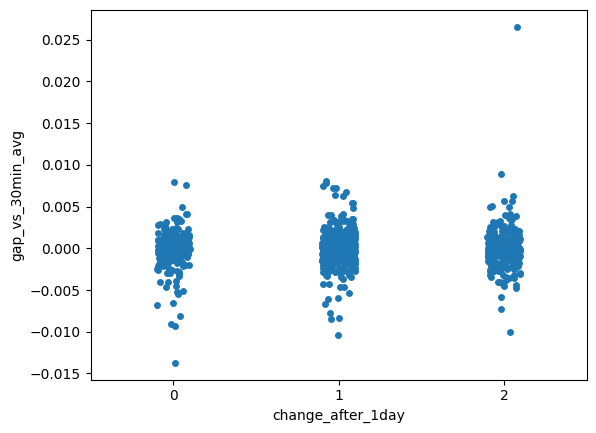

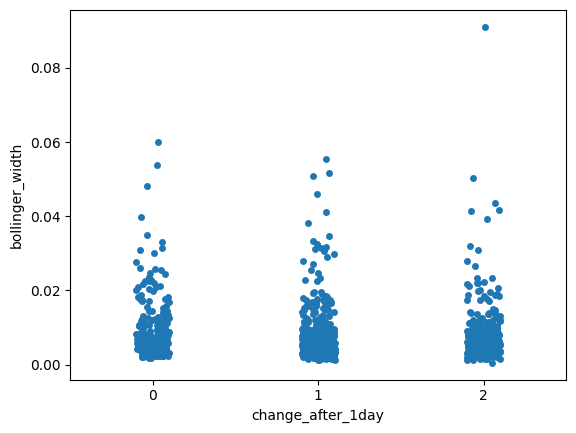

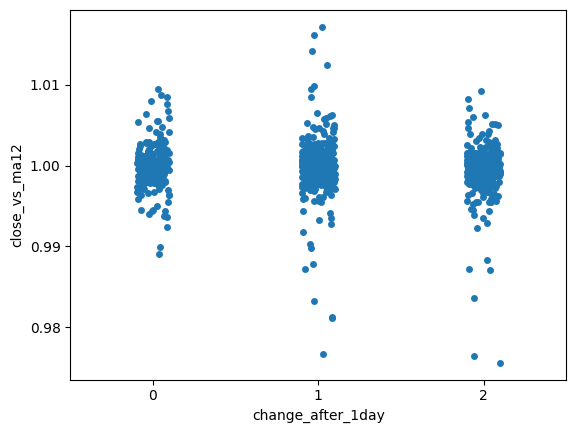

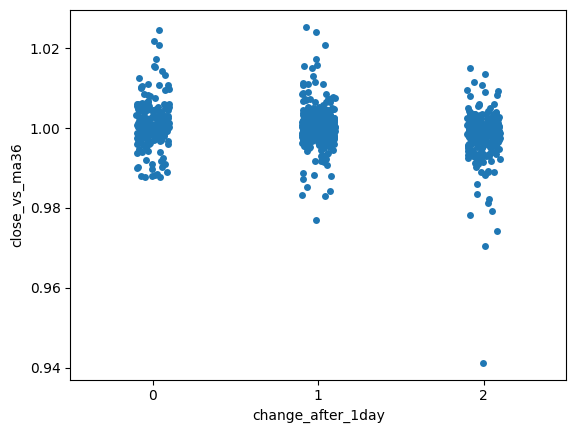

In [16]:
# 분포 
import seaborn as sns
import matplotlib.pyplot as plt

# 전처리
# cv_ai_trainer.load_model_config(cv_ai_trainer.auto_ml_path)
# df_preprocessed = cv_ai_trainer.preprocess_all(df) = df.copy()

# 예: n 개만 랜덤 추출
df_sample = df_combined.sample(n=1000, random_state=42)  

# change_after_1day를 문자열로 캐스팅 (boxplot의 x축을 이산형으로 인식시키기 위해)
df_sample['change_after_1day'] = df_sample['change_after_1day'].astype(str)

for idx, feature in enumerate(cv_ai_trainer.features):
    if idx > 1:
        df_sorted = df_sample.sort_values(by=feature, ascending=False)
        sns.stripplot(x='change_after_1day', y=feature, data=df_sorted, order=['0', '1', '2'])
        plt.show()


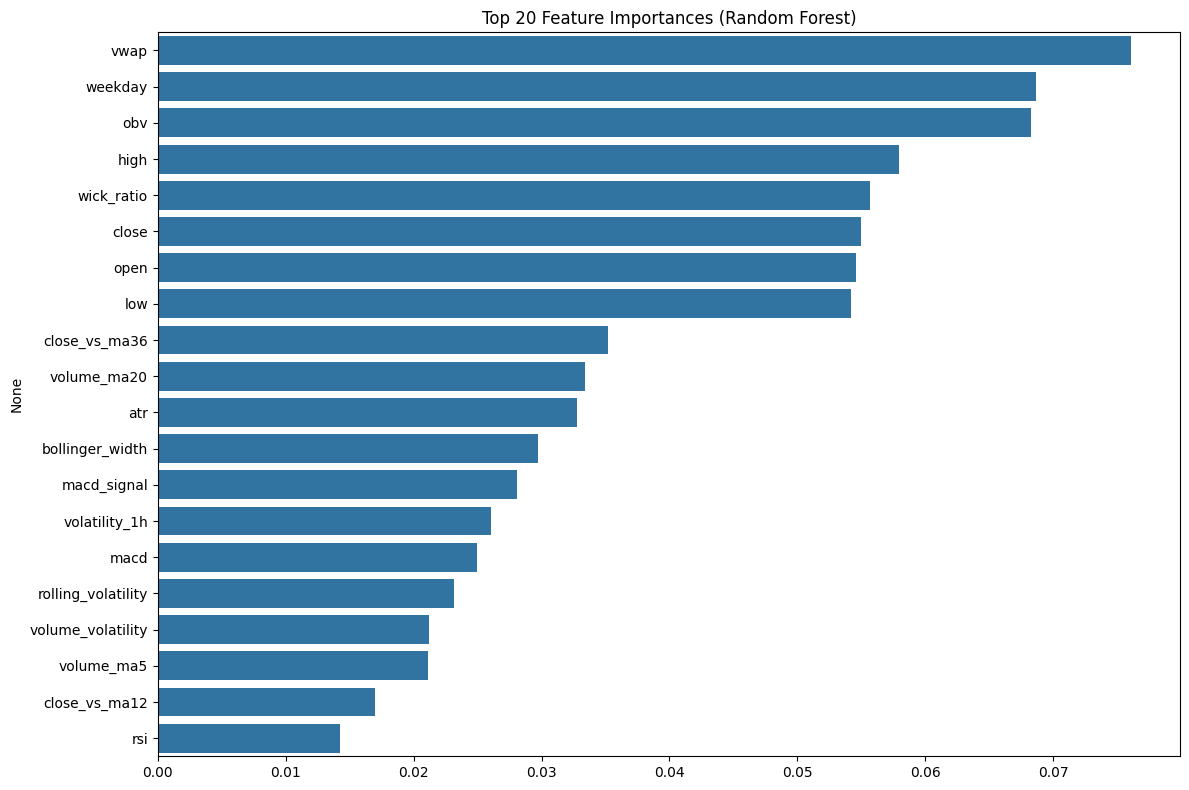

In [32]:
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# 결측치 제외
df_combined.fillna(df_combined.mean(numeric_only=True), inplace=True)

# 1. 숫자형 피처만 선택
X = df_combined[features]
y = df_combined['change_after_1day']

#
X = X.select_dtypes(exclude=['datetime'])

# 2. 학습/검증 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 모델 훈련
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Feature Importance 추출
importances = model.feature_importances_
feature_importance = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

# 5. 시각화
plt.figure(figsize=(12, 8))
sns.barplot(x=feature_importance.values[:20], y=feature_importance.index[:20])
plt.title('Top 20 Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()

In [33]:
# 데이터 셋 업로드 
from shares.modules.minio import *
minio = MinioModule()

# df 업로드        
local_path = "./my_data.xlsx"
minio_path = "/datasets/2025/05/28/2025-05-29 13:00:00.xlsx"

df_combined['tick_datetime'] = df_combined['tick_datetime'].dt.tz_localize(None)
try:
    # Excel 파일로 저장
    df.to_excel(local_path, index=False)  # 현재 작업 디렉토리에 저장
    minio.upload_file(minio_path, local_path)
    
except Exception as e :
    print(e)
    
finally:
    os.remove(local_path)